In [1]:
import ast, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/shots.csv")
print(df.shape)
print(df["shot_outcome"].value_counts())
print(df["shot_type"].value_counts())

(66854, 16)
shot_outcome
Off T               21807
Blocked             16509
Saved               15718
Goal                 7433
Wayward              3557
Post                 1378
Saved Off Target      245
Saved to Post         207
Name: count, dtype: int64
shot_type
Open Play    62279
Free Kick     3524
Penalty       1032
Corner          19
Name: count, dtype: int64


In [2]:
n0 = len(df)
df = df[df["period"] != 5]                      # remove penalty shootouts
df = df[df["shot_type"] != "Penalty"]           # penalties are a different problem (~fixed rate)
df = df.dropna(subset=["location"])

# location is stored as a string like "[96.5, 40.7]" -> split into x, y numbers
xy = df["location"].apply(ast.literal_eval)
df["x"] = xy.str[0]
df["y"] = xy.str[1]

# label: 1 = goal, 0 = anything else
df["goal"] = (df["shot_outcome"] == "Goal").astype(int)

# True/blank flags -> 1/0
for col in ["under_pressure", "shot_first_time"]:
    df[col] = (df[col] == True).astype(int)

print(f"kept {len(df)} of {n0} shots, goal rate = {df['goal'].mean():.3f}")

kept 65822 of 66854 shots, goal rate = 0.101


In [3]:
# StatsBomb pitch is 120 x 80; the goal is at x=120, centred at y=40, posts at y=36 and y=44
df["x"] = df["x"].clip(upper=120)   # shots tagged behind the goal line -> put them on the line
dx = 120 - df["x"]
dy = df["y"] - 40
df["distance"] = np.sqrt(dx**2 + dy**2)
df["angle"] = np.arctan2(8 * dx, dx**2 + dy**2 - 16)   # angle (radians) the goal mouth covers
df["angle_deg"] = np.degrees(df["angle"])
df[["x", "y", "distance", "angle_deg", "goal"]].describe()

,x,y,distance,angle_deg,goal
count,65822.000000,65822.000000,65822.000000,65822.000000,65822.000000
mean,103.320855,39.664237,19.522825,24.766176,0.101288
std,8.880718,10.042077,8.767829,15.407448,0.301712
min,30.200000,0.300000,0.400000,0.000000,0.000000
25%,96.900000,32.100000,12.461541,14.866388,0.000000
50%,104.500000,39.700000,18.959167,19.298075,0.000000
75%,110.500000,47.100000,25.827795,29.864355,0.000000
max,120.000000,79.600000,89.829450,180.000000,1.000000


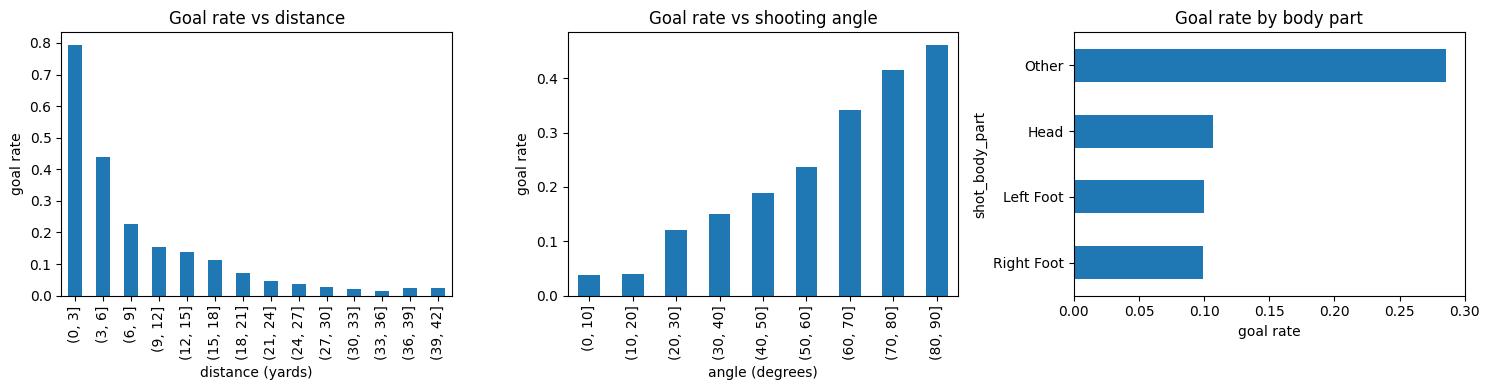

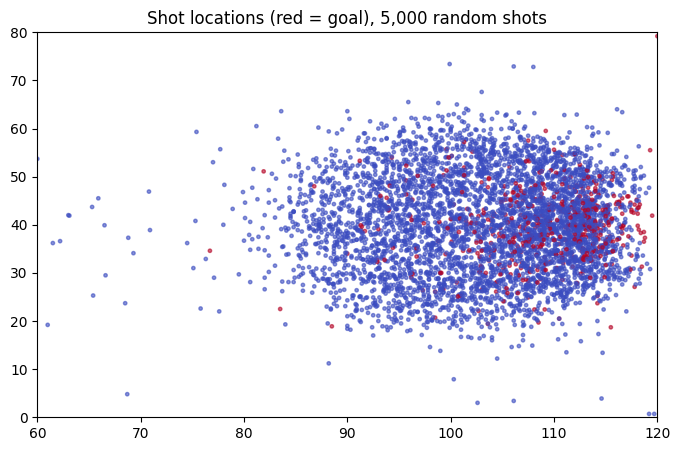

In [4]:
os.makedirs("../figures", exist_ok=True)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# goal rate vs distance
bins = pd.cut(df["distance"], bins=range(0, 45, 3))
df.groupby(bins, observed=True)["goal"].mean().plot(kind="bar", ax=ax[0])
ax[0].set(title="Goal rate vs distance", xlabel="distance (yards)", ylabel="goal rate")

# goal rate vs angle
bins = pd.cut(df["angle_deg"], bins=range(0, 100, 10))
df.groupby(bins, observed=True)["goal"].mean().plot(kind="bar", ax=ax[1])
ax[1].set(title="Goal rate vs shooting angle", xlabel="angle (degrees)", ylabel="goal rate")

# goal rate by body part
df.groupby("shot_body_part")["goal"].mean().sort_values().plot(kind="barh", ax=ax[2])
ax[2].set(title="Goal rate by body part", xlabel="goal rate")

plt.tight_layout()
plt.savefig("../figures/eda_goal_rates.png", dpi=150)
plt.show()

# shot map: where goals come from
plt.figure(figsize=(8, 5))
s = df.sample(5000, random_state=42)
plt.scatter(s["x"], s["y"], c=s["goal"], cmap="coolwarm", s=6, alpha=0.6)
plt.xlim(60, 120); plt.ylim(0, 80)
plt.title("Shot locations (red = goal), 5,000 random shots")
plt.savefig("../figures/shot_map.png", dpi=150)
plt.show()

In [5]:
keep = ["match_id", "competition", "season", "x", "y", "distance", "angle",
        "shot_body_part", "shot_type", "play_pattern", "under_pressure",
        "shot_first_time", "goal", "shot_statsbomb_xg"]
df[keep].to_csv("../data/shots_clean.csv", index=False)
print("saved", len(df), "shots")

saved 65822 shots
